# IDVE Assignment 2: Questions 1-3

This notebook analyses the NYC Taxi Trip Duration training sample. It covers:

1. data cleaning and outlier removal;
2. feature generation; and
3. time-based trip patterns.

All time-based results use pickup time. Counts describe trips recorded in the Kaggle training sample, so they are used as a consistent proxy for taxi activity rather than the complete number of NYC taxi trips.

## Setup and data loading

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
DAY_ORDER = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
BLUE = "#1769AA"
ORANGE = "#E07A1F"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DATA_PATH = Path("nyc-taxi-trip-duration/train/train.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Run the notebook from the assignment folder."
    )

raw_df = pd.read_csv(DATA_PATH)
raw_df["pickup_datetime"] = pd.to_datetime(raw_df["pickup_datetime"])
raw_df["dropoff_datetime"] = pd.to_datetime(raw_df["dropoff_datetime"])

print(f"Rows: {len(raw_df):,}")
print(f"Columns: {raw_df.shape[1]}")
print(
    f"Pickup period: {raw_df['pickup_datetime'].min()} to "
    f"{raw_df['pickup_datetime'].max()}"
)
print(f"Missing values: {raw_df.isna().sum().sum():,}")
display(raw_df.head())

Rows: 1,458,644
Columns: 11
Pickup period: 2016-01-01 00:00:17 to 2016-06-30 23:59:39
Missing values: 0


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


The file contains 1,458,644 trips from 1 January to 30 June 2016. No fields are missing, but the absence of missing values does not mean every value is plausible. The duration, coordinates, passenger count, distance and implied speed must still be checked.

## Question 1: Data cleaning

### Initial feature calculation

Distance and speed are calculated before filtering because they reveal records that are internally inconsistent. The Haversine formula gives the great-circle distance between the pickup and drop-off coordinates. This is a straight-line distance, not road distance, so it normally underestimates the distance driven. It is still suitable for detecting clear coordinate and speed errors.

In [2]:
def haversine_km(lon1, lat1, lon2, lat2):
    """Vectorised great-circle distance in kilometres."""
    lon1, lat1, lon2, lat2 = map(
        np.radians, [lon1, lat1, lon2, lat2]
    )
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    )
    return 6371.0088 * 2 * np.arcsin(np.sqrt(a))


raw_df["distance_km"] = haversine_km(
    raw_df["pickup_longitude"],
    raw_df["pickup_latitude"],
    raw_df["dropoff_longitude"],
    raw_df["dropoff_latitude"],
)
raw_df["trip_duration_min"] = raw_df["trip_duration"] / 60
raw_df["average_speed_kmh"] = (
    raw_df["distance_km"] / (raw_df["trip_duration"] / 3600)
)

diagnostic_columns = [
    "trip_duration_min", "distance_km", "average_speed_kmh",
    "passenger_count", "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude"
]
display(
    raw_df[diagnostic_columns]
    .describe(percentiles=[0.001, 0.01, 0.50, 0.99, 0.999])
    .T
    .round(3)
)

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
trip_duration_min,1458644.0,15.992,87.291,0.017,0.117,1.450,11.033,57.333,1418.806,58771.367
distance_km,1458644.0,3.441,4.297,0.000,0.000,0.139,2.094,20.788,24.767,1240.910
average_speed_kmh,1458644.0,14.423,14.978,0.000,0.000,1.394,12.792,40.745,54.302,9274.850
passenger_count,1458644.0,1.665,1.314,0.000,1.000,1.000,1.000,6.000,6.000,9.000
pickup_longitude,1458644.0,-73.973,0.071,-121.933,-74.017,-74.014,-73.982,-73.782,-73.777,-61.336
pickup_latitude,1458644.0,40.751,0.033,34.360,40.642,40.645,40.754,40.807,40.842,51.881
dropoff_longitude,1458644.0,-73.973,0.071,-121.933,-74.178,-74.015,-73.980,-73.790,-73.740,-61.336
dropoff_latitude,1458644.0,40.752,0.036,32.181,40.604,40.645,40.755,40.837,40.890,43.921


### Cleaning rules

The rules below remove values that are either invalid or implausible for an ordinary NYC taxi trip.

- **Duration:** keep 30 seconds to 4 hours. Trips lasting only a few seconds are unlikely to be completed passenger trips, while multi-day durations indicate meter or timestamp errors.
- **Distance:** keep 0.05 km to 100 km. Near-zero displacement makes speed unreliable and usually indicates a cancelled, stationary or faulty record. The upper limit is generous enough for trips across the wider metropolitan area.
- **Average speed:** keep values at or below 120 km/h. This is already a generous upper bound for an average speed through New York and accounts for the Haversine distance being shorter than the driven route.
- **Coordinates:** keep pickups and drop-offs inside the broad NYC metropolitan box, longitude -74.3 to -73.7 and latitude 40.5 to 41.0. This includes Manhattan, JFK, LaGuardia and Newark while removing points far outside the study area.
- **Passengers:** keep 1 to 6 passengers. Zero is not a valid passenger trip, and values above six exceed the normal recorded taxi capacity in this dataset.

These limits combine domain plausibility with the empirical tails shown above. They are deliberately broad so that unusual but credible trips remain in the analysis.

In [3]:
rules = {
    "Duration outside 30 s to 4 h": ~raw_df["trip_duration"].between(30, 4 * 3600),
    "Distance outside 0.05 to 100 km": ~raw_df["distance_km"].between(0.05, 100),
    "Average speed above 120 km/h": (
        ~np.isfinite(raw_df["average_speed_kmh"])
        | (raw_df["average_speed_kmh"] > 120)
    ),
    "Pickup or drop-off outside NYC metro box": ~(
        raw_df["pickup_longitude"].between(-74.3, -73.7)
        & raw_df["dropoff_longitude"].between(-74.3, -73.7)
        & raw_df["pickup_latitude"].between(40.5, 41.0)
        & raw_df["dropoff_latitude"].between(40.5, 41.0)
    ),
    "Passenger count outside 1 to 6": ~raw_df["passenger_count"].between(1, 6),
}

rule_summary = pd.DataFrame(
    {
        "criterion": rules.keys(),
        "rows_flagged": [mask.sum() for mask in rules.values()],
    }
)
rule_summary["percentage_of_raw"] = (
    100 * rule_summary["rows_flagged"] / len(raw_df)
)
display(rule_summary.style.format({
    "rows_flagged": "{:,}",
    "percentage_of_raw": "{:.3f}%",
}))

invalid_mask = np.logical_or.reduce(list(rules.values()))
clean_df = raw_df.loc[~invalid_mask].copy()

removed = int(invalid_mask.sum())
print(f"Rows before cleaning: {len(raw_df):,}")
print(f"Rows removed:         {removed:,} ({removed / len(raw_df):.2%})")
print(f"Rows after cleaning:  {len(clean_df):,}")

Rows before cleaning: 1,458,644
Rows removed:         15,109 (1.04%)
Rows after cleaning:  1,443,535


,criterion,rows_flagged,percentage_of_raw
0,Duration outside 30 s to 4 h,"6,859",0.470%
1,Distance outside 0.05 to 100 km,"11,348",0.778%
2,Average speed above 120 km/h,136,0.009%
3,Pickup or drop-off outside NYC metro box,998,0.068%
4,Passenger count outside 1 to 6,65,0.004%


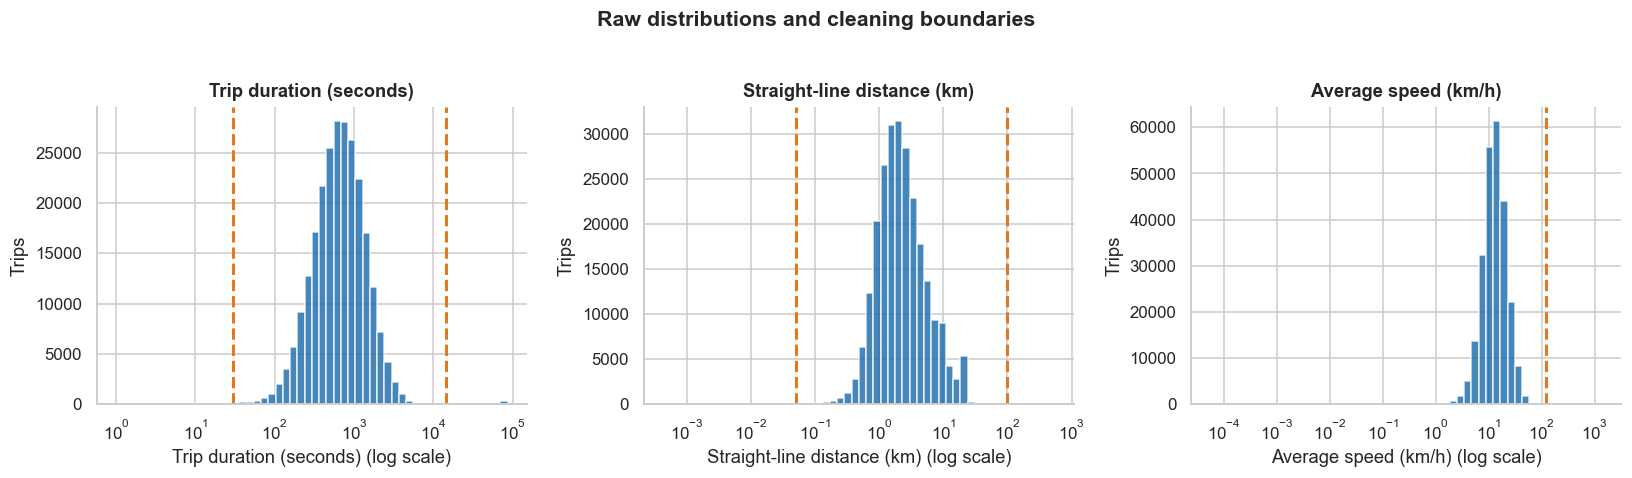

,count,mean,std,min,1%,50%,95%,99%,max
trip_duration_min,1443535.0,14.00,10.97,0.50,1.75,11.07,34.75,55.18,237.38
distance_km,1443535.0,3.45,3.89,0.05,0.35,2.11,11.01,20.75,47.77
average_speed_kmh,1443535.0,14.47,7.64,0.03,3.16,12.85,29.40,40.48,117.62


In [4]:
# Plot a reproducible sample because drawing every raw value is unnecessary.
plot_sample = raw_df.sample(n=min(250_000, len(raw_df)), random_state=SEED)

plot_specs = [
    ("trip_duration", "Trip duration (seconds)", [30, 4 * 3600]),
    ("distance_km", "Straight-line distance (km)", [0.05, 100]),
    ("average_speed_kmh", "Average speed (km/h)", [120]),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (column, label, limits) in zip(axes, plot_specs):
    values = plot_sample.loc[
        np.isfinite(plot_sample[column]) & (plot_sample[column] > 0), column
    ]
    bins = np.geomspace(values.min(), values.max(), 55)
    ax.hist(values, bins=bins, color=BLUE, alpha=0.80)
    ax.set_xscale("log")
    for boundary in limits:
        ax.axvline(boundary, color=ORANGE, linestyle="--", linewidth=2)
    ax.set_xlabel(label + " (log scale)")
    ax.set_ylabel("Trips")
    ax.set_title(label)

fig.suptitle(
    "Raw distributions and cleaning boundaries",
    y=1.03,
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

display(
    clean_df[["trip_duration_min", "distance_km", "average_speed_kmh"]]
    .describe(percentiles=[0.01, 0.50, 0.95, 0.99])
    .T
    .round(2)
)

The filters remove **15,109 trips (1.04%)**, leaving **1,443,535 trips**. Most removed rows have extremely small displacement, while smaller groups contain implausible durations, coordinates, speeds or passenger counts. Because the rules overlap, the individual counts in the table should not be added together. The cleaned sample retains about 99% of the data, so the analysis is not being driven by aggressive trimming.

## Question 2: Feature generation

In [5]:
clean_df["date"] = clean_df["pickup_datetime"].dt.date
clean_df["hour"] = clean_df["pickup_datetime"].dt.hour
clean_df["day_of_week_num"] = clean_df["pickup_datetime"].dt.dayofweek
clean_df["day_of_week"] = pd.Categorical(
    clean_df["pickup_datetime"].dt.day_name(),
    categories=DAY_ORDER,
    ordered=True,
)
clean_df["is_weekend"] = clean_df["day_of_week_num"] >= 5
clean_df["day_type"] = np.where(clean_df["is_weekend"], "Weekend", "Weekday")

feature_dictionary = pd.DataFrame({
    "feature": [
        "distance_km", "day_of_week", "day_of_week_num", "hour",
        "average_speed_kmh", "date", "is_weekend", "day_type"
    ],
    "definition": [
        "Haversine distance from pickup to drop-off",
        "Ordered pickup weekday name",
        "Pickup weekday number, Monday=0 and Sunday=6",
        "Pickup hour from 0 to 23",
        "Distance divided by duration in hours",
        "Pickup calendar date",
        "True for Saturday or Sunday",
        "Weekday/weekend label",
    ],
})
display(feature_dictionary)

display(
    clean_df[[
        "pickup_datetime", "trip_duration_min", "distance_km",
        "average_speed_kmh", "day_of_week", "hour", "day_type"
    ]].head(10).round(2)
)

,feature,definition
0,distance_km,Haversine distance from pickup to drop-off
1,day_of_week,Ordered pickup weekday name
2,day_of_week_num,"Pickup weekday number, Monday=0 and Sunday=6"
3,hour,Pickup hour from 0 to 23
4,average_speed_kmh,Distance divided by duration in hours
5,date,Pickup calendar date
6,is_weekend,True for Saturday or Sunday
7,day_type,Weekday/weekend label


,pickup_datetime,trip_duration_min,distance_km,average_speed_kmh,day_of_week,hour,day_type
0,2016-03-14 17:24:55,7.58,1.50,11.86,Monday,17,Weekday
1,2016-06-12 00:43:35,11.05,1.81,9.80,Sunday,0,Weekend
2,2016-01-19 11:35:24,35.40,6.39,10.82,Tuesday,11,Weekday
3,2016-04-06 19:32:31,7.15,1.49,12.47,Wednesday,19,Weekday
4,2016-03-26 13:30:55,7.25,1.19,9.84,Saturday,13,Weekend
5,2016-01-30 22:01:40,7.38,1.10,8.93,Saturday,22,Weekend
6,2016-06-17 22:34:59,5.68,1.33,14.00,Friday,22,Weekday
7,2016-05-21 07:54:58,25.85,5.71,13.26,Saturday,7,Weekend
8,2016-05-27 23:12:23,4.25,1.31,18.50,Friday,23,Weekday
9,2016-03-10 21:45:01,20.42,5.12,15.05,Thursday,21,Weekday


The three required features are `distance_km`, `day_of_week` and `average_speed_kmh`. The additional time fields make the later analysis direct and reproducible. `day_of_week` is ordered from Monday to Sunday so tables and plots appear in calendar order rather than alphabetical order.

## Question 3: Time-based analysis

### 3.1 Most popular day of the week

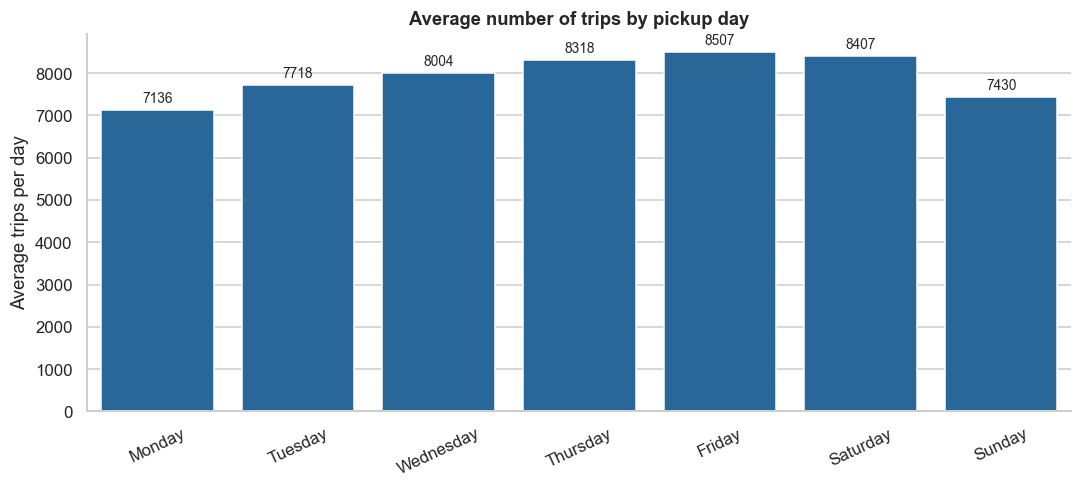

,total_trips,mean_daily_trips
day_of_week,,
Monday,185525,7135.6
Tuesday,200673,7718.2
Wednesday,208116,8004.5
Thursday,216264,8317.8
Friday,221194,8507.5
Saturday,218579,8406.9
Sunday,193184,7430.2


In [6]:
daily_counts = (
    clean_df.groupby(["date", "day_of_week"], observed=True)
    .size()
    .rename("trips")
    .reset_index()
)

weekday_summary = (
    daily_counts.groupby("day_of_week", observed=True)["trips"]
    .agg(total_trips="sum", mean_daily_trips="mean")
    .reindex(DAY_ORDER)
)

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.barplot(
    data=weekday_summary.reset_index(),
    x="day_of_week",
    y="mean_daily_trips",
    color=BLUE,
    ax=ax,
)
ax.set_title("Average number of trips by pickup day")
ax.set_xlabel("")
ax.set_ylabel("Average trips per day")
ax.tick_params(axis="x", rotation=25)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)
plt.tight_layout()
plt.show()

display(weekday_summary.round(1))

**Friday is the most popular day**, with about **8,508 trips per day** in the training sample. Saturday is close at about 8,407. The sample covers exactly 26 occurrences of each weekday, so total counts give the same ranking, but the daily average remains the clearer comparison.

### 3.2 Most popular hour on each day

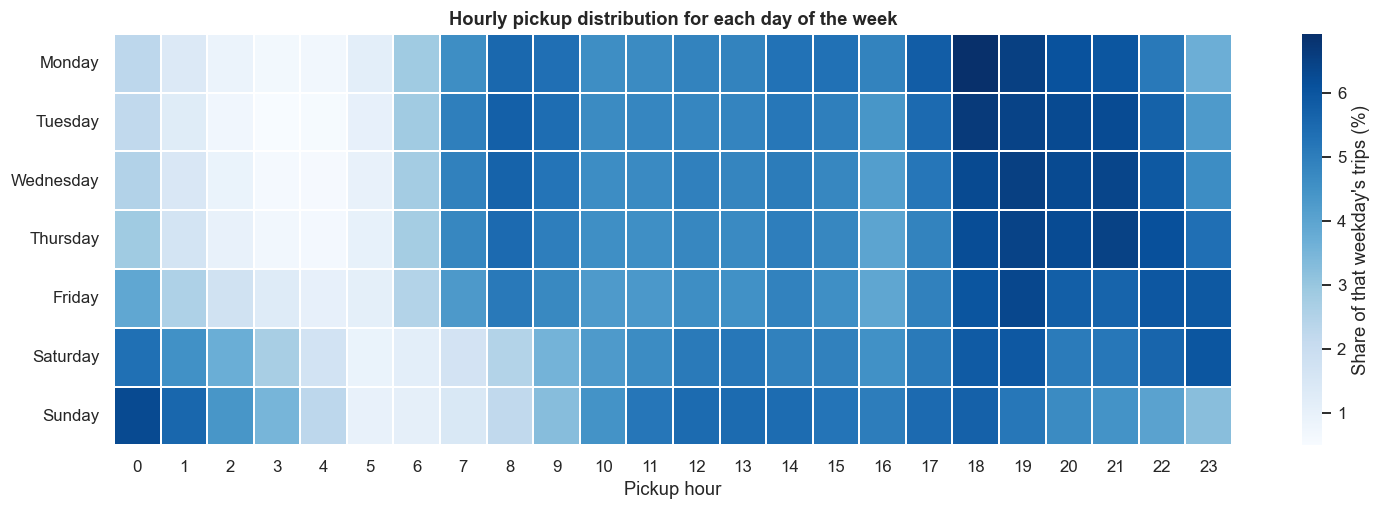

,hour,trips,share_percent
day_of_week,,,
Monday,18,12838,6.92
Tuesday,18,13347,6.65
Wednesday,19,13586,6.53
Thursday,21,14026,6.49
Friday,19,14039,6.35
Saturday,23,13057,5.97
Sunday,0,12153,6.29


In [7]:
weekday_hour = (
    clean_df.groupby(["day_of_week", "hour"], observed=False)
    .size()
    .rename("trips")
    .reset_index()
)

# Use a within-day percentage so the colour shows each day's hourly shape.
weekday_hour["share_percent"] = (
    100
    * weekday_hour["trips"]
    / weekday_hour.groupby(
        "day_of_week", observed=False
    )["trips"].transform("sum")
)

heatmap_data = weekday_hour.pivot(
    index="day_of_week", columns="hour", values="share_percent"
).reindex(DAY_ORDER)

fig, ax = plt.subplots(figsize=(14, 4.8))
sns.heatmap(
    heatmap_data,
    cmap="Blues",
    linewidths=0.25,
    cbar_kws={"label": "Share of that weekday's trips (%)"},
    ax=ax,
)
ax.set_title("Hourly pickup distribution for each day of the week")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

peak_hours = (
    weekday_hour.loc[
        weekday_hour.groupby(
            "day_of_week", observed=False
        )["trips"].idxmax(),
        ["day_of_week", "hour", "trips", "share_percent"],
    ]
    .set_index("day_of_week")
    .reindex(DAY_ORDER)
)
display(peak_hours.round({"share_percent": 2}))

The most popular pickup hour changes through the week:

- Monday and Tuesday peak at **18:00**.
- Wednesday peaks at **19:00**.
- Thursday peaks later at **21:00**.
- Friday peaks at **19:00**.
- Saturday peaks at **23:00**.
- Sunday peaks at **00:00**.

The Monday-to-Wednesday peaks are consistent with evening commuting and after-work activity. Thursday and Friday remain busy later, while the Saturday and Sunday midnight peaks are consistent with nightlife trips crossing into the early morning. These are plausible explanations, but the trip records do not contain journey purpose, so they cannot prove why passengers travelled.

### 3.3 Weekdays compared with weekends

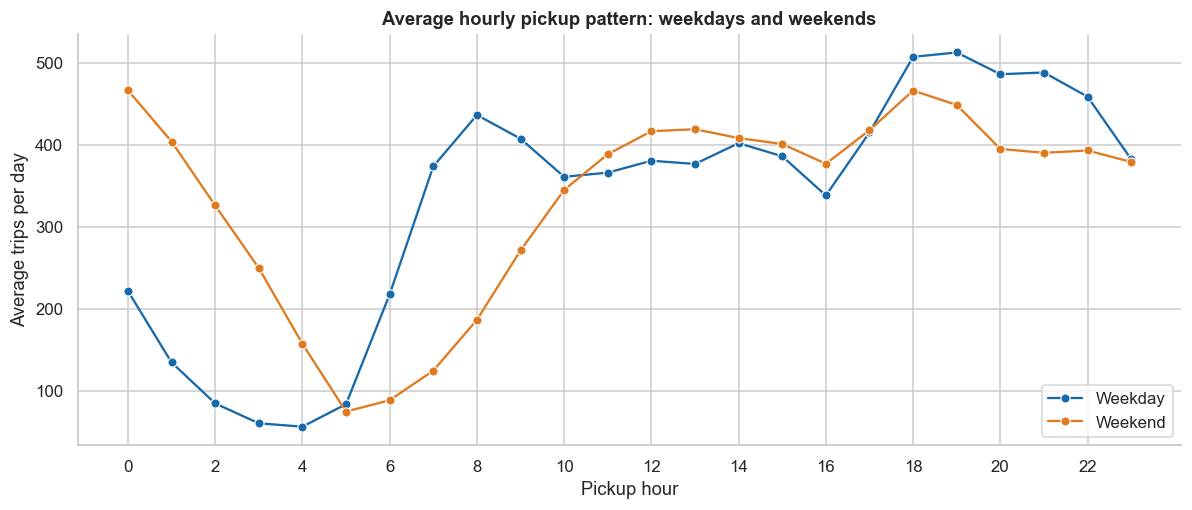

,trips,number_of_days,median_duration_min,median_distance_km,mean_speed_kmh,mean_trips_per_day
day_type,,,,,,
Weekday,1031772,130,11.38,2.07,13.92,7936.71
Weekend,411763,52,10.37,2.22,15.84,7918.52


In [8]:
date_hour = (
    clean_df.groupby(["date", "day_type", "hour"])
    .size()
    .rename("trips")
    .reset_index()
)
hourly_day_type = (
    date_hour.groupby(["day_type", "hour"])["trips"]
    .mean()
    .rename("average_trips_per_day")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.lineplot(
    data=hourly_day_type,
    x="hour",
    y="average_trips_per_day",
    hue="day_type",
    hue_order=["Weekday", "Weekend"],
    palette=[BLUE, ORANGE],
    marker="o",
    ax=ax,
)
ax.set_title("Average hourly pickup pattern: weekdays and weekends")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Average trips per day")
ax.set_xticks(range(0, 24, 2))
ax.legend(title="")
plt.tight_layout()
plt.show()

day_type_summary = (
    clean_df.groupby("day_type")
    .agg(
        trips=("id", "size"),
        number_of_days=("date", "nunique"),
        median_duration_min=("trip_duration_min", "median"),
        median_distance_km=("distance_km", "median"),
        mean_speed_kmh=("average_speed_kmh", "mean"),
    )
)
day_type_summary["mean_trips_per_day"] = (
    day_type_summary["trips"] / day_type_summary["number_of_days"]
)
display(day_type_summary.round(2))

Weekdays have clear morning and evening commuter patterns, with the largest rise around 17:00-19:00. Weekend activity starts later in the morning and remains stronger late at night, especially from 22:00 to 01:00. Average daily volume is almost the same: about **7,937 weekday trips** and **7,919 weekend trips** in the sample. The difference is mainly when people travel, not how many trips occur across a full day. Weekend trips are also slightly longer and faster, which is consistent with lighter traffic and a different mix of destinations.

### 3.4 Major holidays

The relevant 2016 dates are:

- Martin Luther King Jr. Day: **18 January 2016**
- Valentine's Day: **14 February 2016**
- St. Patrick's Day: **17 March 2016**
- Easter Sunday: **27 March 2016**
- Memorial Day: **30 May 2016**

Each holiday is compared with the median hourly profile of the same weekday, excluding all five named holidays. Matching the weekday is necessary because normal Monday and Sunday patterns are already different.

In [9]:
holidays = {
    "Martin Luther King Jr. Day": "2016-01-18",
    "Valentine's Day": "2016-02-14",
    "St. Patrick's Day": "2016-03-17",
    "Easter Sunday": "2016-03-27",
    "Memorial Day": "2016-05-30",
}
holiday_dates = {pd.Timestamp(value).date() for value in holidays.values()}

holiday_profiles = {}
typical_profiles = {}
holiday_rows = []

for holiday, date_string in holidays.items():
    timestamp = pd.Timestamp(date_string)
    date = timestamp.date()
    weekday = timestamp.day_name()

    actual = (
        clean_df.loc[clean_df["date"] == date]
        .groupby("hour")
        .size()
        .reindex(range(24), fill_value=0)
    )

    comparison = clean_df.loc[
        (clean_df["day_of_week"].astype(str) == weekday)
        & (~clean_df["date"].isin(holiday_dates))
    ]
    comparison_matrix = (
        comparison.groupby(["date", "hour"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=range(24), fill_value=0)
    )
    typical = comparison_matrix.median(axis=0)

    holiday_profiles[holiday] = actual
    typical_profiles[holiday] = typical

    typical_total = typical.sum()
    holiday_rows.append({
        "holiday": holiday,
        "date": date_string,
        "weekday": weekday,
        "holiday_trips": int(actual.sum()),
        "typical_same_weekday": typical_total,
        "change_percent": 100 * (actual.sum() / typical_total - 1),
        "holiday_peak_hour": int(actual.idxmax()),
        "typical_peak_hour": int(typical.idxmax()),
    })

holiday_summary = pd.DataFrame(holiday_rows).set_index("holiday")
display(holiday_summary.round({
    "typical_same_weekday": 1,
    "change_percent": 1,
}))

,date,weekday,holiday_trips,typical_same_weekday,change_percent,holiday_peak_hour,typical_peak_hour
holiday,,,,,,,
Martin Luther King Jr. Day,2016-01-18,Monday,7060,7166.5,-1.5,18,18
Valentine's Day,2016-02-14,Sunday,8393,7556.0,11.1,17,0
St. Patrick's Day,2016-03-17,Thursday,8167,8324.0,-1.9,20,21
Easter Sunday,2016-03-27,Sunday,7290,7556.0,-3.5,0,0
Memorial Day,2016-05-30,Monday,5513,7166.5,-23.1,16,18


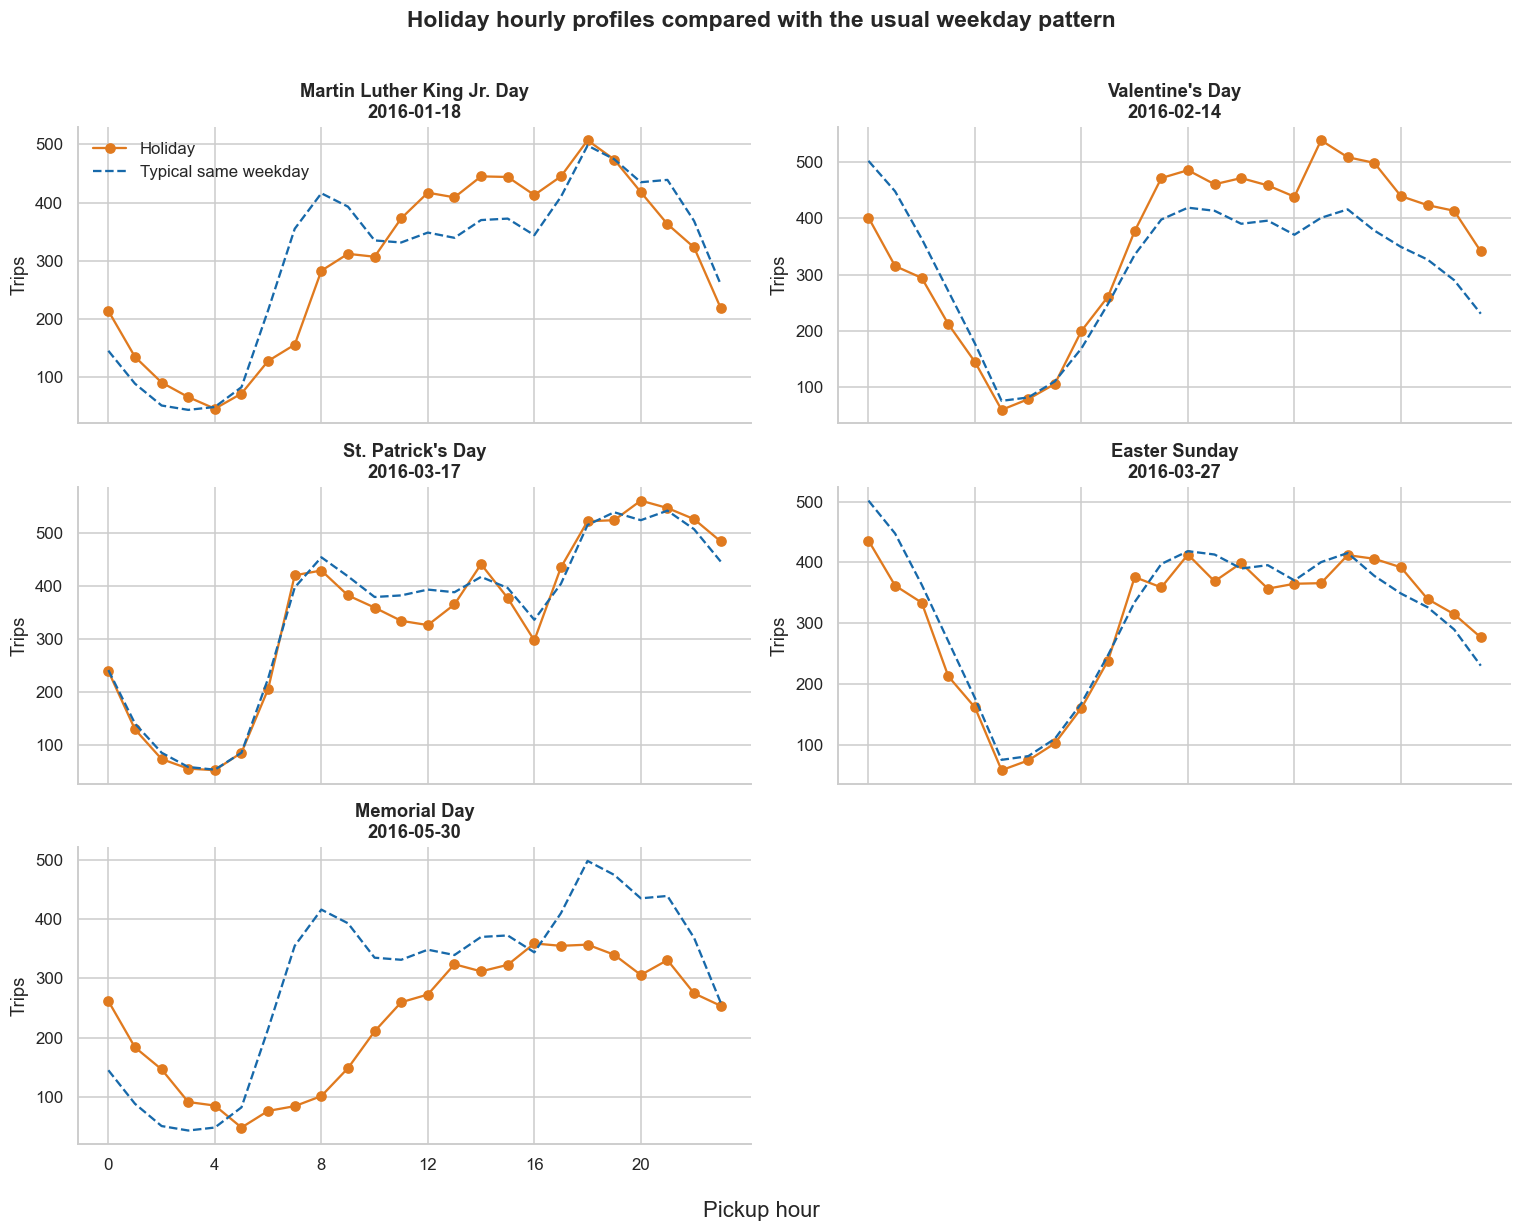

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
axes = axes.flatten()

for ax, holiday in zip(axes, holidays):
    actual = holiday_profiles[holiday]
    typical = typical_profiles[holiday]
    ax.plot(
        range(24),
        actual.values,
        color=ORANGE,
        marker="o",
        label="Holiday",
    )
    ax.plot(
        range(24),
        typical.values,
        color=BLUE,
        linestyle="--",
        label="Typical same weekday",
    )
    ax.set_title(f"{holiday}\n{holidays[holiday]}")
    ax.set_ylabel("Trips")
    ax.set_xticks(range(0, 24, 4))

axes[0].legend(frameon=False)
axes[-1].axis("off")
fig.supxlabel("Pickup hour")
fig.suptitle(
    "Holiday hourly profiles compared with the usual weekday pattern",
    y=1.01,
    fontsize=15,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

Holiday effects are not uniform.

- **Memorial Day changes the pattern most.** It has about **23% fewer trips** than a typical Monday and peaks at 16:00 instead of 18:00. A public holiday removes much of the normal commuter peak.
- **Valentine's Day has about 11% more trips** than a typical Sunday. Its peak moves from midnight to 17:00, which is consistent with additional early-evening social travel.
- **Easter Sunday is about 4% quieter** than a typical Sunday and has a weaker profile through much of the day.
- **Martin Luther King Jr. Day and St. Patrick's Day have totals close to their usual weekdays**, although their hourly shapes show local shifts.

This comparison shows why total volume alone is not enough: a holiday can alter the timing of demand even when the daily total changes little.

### 3.5 Average speed throughout the day

Highest mean speed: 05:00 (24.58 km/h)
Lowest mean speed:  15:00 (12.14 km/h)


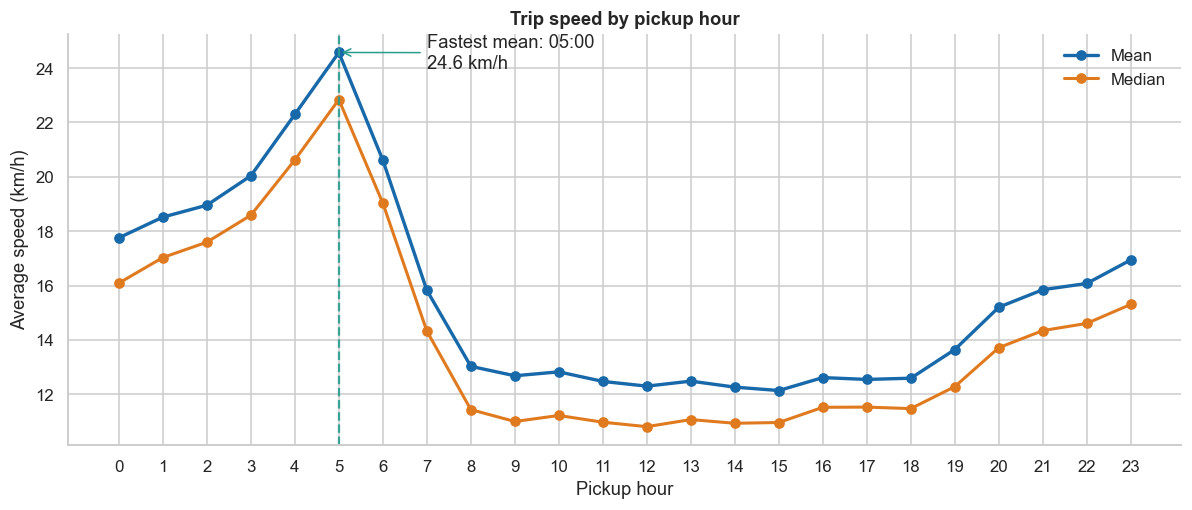

,mean_speed_kmh,median_speed_kmh,trips
hour,,,
0,17.76,16.09,52616
1,18.52,17.03,38100
2,18.96,17.60,27629
3,20.04,18.59,20580
4,22.30,20.62,15490
5,24.58,22.84,14758
6,20.61,19.03,32886
7,15.83,14.33,55051
8,13.03,11.43,66422


In [11]:
speed_by_hour = (
    clean_df.groupby("hour")["average_speed_kmh"]
    .agg(mean_speed_kmh="mean", median_speed_kmh="median", trips="size")
)

fastest_mean_hour = int(speed_by_hour["mean_speed_kmh"].idxmax())
slowest_mean_hour = int(speed_by_hour["mean_speed_kmh"].idxmin())

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(
    speed_by_hour.index,
    speed_by_hour["mean_speed_kmh"],
    color=BLUE,
    marker="o",
    linewidth=2.2,
    label="Mean",
)
ax.plot(
    speed_by_hour.index,
    speed_by_hour["median_speed_kmh"],
    color=ORANGE,
    marker="o",
    linewidth=2,
    label="Median",
)
ax.axvline(
    fastest_mean_hour,
    color="#2A9D8F",
    linestyle="--",
    alpha=0.9,
)
ax.annotate(
    f"Fastest mean: {fastest_mean_hour:02d}:00\n"
    f"{speed_by_hour.loc[fastest_mean_hour, 'mean_speed_kmh']:.1f} km/h",
    xy=(
        fastest_mean_hour,
        speed_by_hour.loc[fastest_mean_hour, "mean_speed_kmh"],
    ),
    xytext=(7, 24),
    arrowprops={"arrowstyle": "->", "color": "#2A9D8F"},
)
ax.set_title("Trip speed by pickup hour")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Average speed (km/h)")
ax.set_xticks(range(24))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

display(speed_by_hour.round(2))
print(
    f"Highest mean speed: {fastest_mean_hour:02d}:00 "
    f"({speed_by_hour.loc[fastest_mean_hour, 'mean_speed_kmh']:.2f} km/h)"
)
print(
    f"Lowest mean speed:  {slowest_mean_hour:02d}:00 "
    f"({speed_by_hour.loc[slowest_mean_hour, 'mean_speed_kmh']:.2f} km/h)"
)

Trips are fastest at **05:00**, when the mean speed is about **24.6 km/h** and the median is about **22.8 km/h**. Speed falls sharply as the morning commute begins and remains low through the working day. The lowest mean occurs at **15:00**, at about **12.1 km/h**. Speeds then rise again after 19:00. The mean and median follow the same shape, so the result is not caused only by a small number of unusually fast trips. Traffic congestion is the most plausible explanation, although route mix and trip distance may also change by hour.

## Main findings

- The cleaning rules remove 1.04% of records while retaining 1,443,535 plausible trips.
- Friday has the highest average daily pickup count.
- Weekday demand peaks around the evening commute; weekend activity shifts toward late night.
- Memorial Day has the clearest holiday reduction, while Valentine's Day has higher activity than a typical Sunday.
- Average speeds are highest around 05:00 and lowest during the congested daytime period.